# Eksperimen Pribadi — Tugas 3: Integrasi Multimodal — **Late Fusion**

**Late fusion** = tiap sumber informasi punya **sub-model unimodal sendiri** yang dilatih terpisah; yang digabung adalah **keluaran prediksinya** (nilai return untuk regresi, **logit/probabilitas naik** untuk arah), bukan fiturnya. Kebalikan dari early fusion (notebook sebelumnya) yang menggabungkan fitur sebelum satu model.

**Pakar (sub-model unimodal)**

| Pakar | Modalitas | Model |
|---|---|---|
| `kurs` | numerik (7 fitur kurs) | Ridge + RandomForest + GradBoost (= Model A) |
| `gru` | **temporal** valas | GRU atas 20 return terakhir (jaringan kecil) |
| `lex` | lexicon | model tabular atas 16 fitur lexicon |
| `finbert` | teks | model tabular atas FinBERT-PCA10 + 6 sentimen |
| `head` | teks (**head atas Transformer beku**) | MLP kecil atas embedding FinBERT harian 768-d |
| `topic` | teks | model tabular atas porsi tema BERTopic |
| `ner` | teks | model tabular atas porsi entitas |

Tiap pakar menghasilkan **dua keluaran**: prediksi return (regresi) dan **logit arah naik** (klasifikasi, `y > 0`).

**Aturan penggabungan**
- **Rata-rata**: rata-rata prediksi (regresi) atau rata-rata logit (arah).
- **Stacking**: model meta dilatih pada **prediksi out-of-fold** pakar (regresi: kuadrat terkecil dengan bobot **non-negatif**; arah: regresi logistik atas logit pakar). Out-of-fold dibuat dengan validasi berurutan (expanding window) hanya di train, jadi meta-model tidak melihat prediksi in-sample pakar dan **tidak bocor** ke val/test.

**Dua jalur evaluasi**
1. **Regresi (error):** protokol sama dengan notebook sebelumnya (RMSE, dRMSE% terhadap A, terhadap Konstan; block bootstrap).
2. **Arah (probabilitas):** AUC, BalAcc, MCC, log-loss terhadap prior train.

Pembanding langsung: **early fusion** (C3/C4/FULL) dengan pakar tabular yang sama, supaya selisih early vs late bersih.

**Prasyarat cache:** sama dengan early fusion (FinBERT, MiniLM, NER) di `cache_embeddings/`.

## 0. Setup

In [1]:
import sys, re, json, time, pickle, warnings
from collections import Counter
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    """Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/)."""
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split

In [2]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


In [3]:
is_tr = (articles["split"] == "train").to_numpy(); has_split = articles["split"].notna().to_numpy()
has_news = (daily["news_count"] > 0).to_numpy()
texts = articles["text_raw"].tolist()

def daily_mean(M):
    '''Rata-rata per aligned_trading_date; hari tanpa berita = rata-rata hari train (netral).'''
    df = pd.DataFrame(M[has_split]); df["date"] = articles.loc[has_split, "aligned_trading_date"].to_numpy()
    d = df.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); out = d.to_numpy(float).copy()
    out[~has] = out[tr & has].mean(axis=0)
    return out

BLK = {}      # nama blok -> (matriks harian, nama kolom)
BLK["kurs"] = (daily[KURS_COLS].to_numpy(), KURS_COLS)
BLK["lex"] = (daily[LEX_COLS].to_numpy(), LEX_COLS)
print({k: v[0].shape for k, v in BLK.items()})

{'kurs': (1194, 7), 'lex': (1194, 16)}


## 2. Blok emb dan sent (FinBERT)
Embedding artikel dirata-rata per hari lalu PCA 10 komponen (**fit hanya hari train**); hari tanpa berita = 0 di ruang PCA. Sentimen = 6 fitur harian dari probabilitas FinBERT.

In [4]:
KS = (5, 10, 20)

def pca_daily(A, kmax=max(KS)):
    keep = articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); D = d.to_numpy(dtype=float)
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[tr & has])        # TRAIN saja
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    return {k: Z[:, :k] for k in KS}, int(has.sum()), float(pca.explained_variance_ratio_.sum())

def finbert_daily(P, labels):
    idx = {v: k for k, v in labels.items()}
    pos, neg, neu = P[:, idx["positive"]], P[:, idx["negative"]], P[:, idx["neutral"]]
    keep = articles["split"].notna().to_numpy()
    df = pd.DataFrame({"fb_pos": pos, "fb_neg": neg, "fb_neu": neu, "net": pos - neg})[keep]
    df["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    g = df.groupby("date")
    out = pd.DataFrame({"fb_pos_mean": g["fb_pos"].mean(), "fb_neg_mean": g["fb_neg"].mean(),
                        "fb_neu_mean": g["fb_neu"].mean(), "fb_net_mean": g["net"].mean(),
                        "fb_net_min": g["net"].min(), "fb_net_max": g["net"].max()})
    return out.reindex(daily["date"]).fillna(0.0).to_numpy()

fb_f = CACHE_DIR / "FinBERT_cw300_mc2_ml512.npz"
if fb_f.exists():
    z = np.load(fb_f, allow_pickle=True); assert len(z["A"]) == len(articles)
    Zs, n_days, evr = pca_daily(z["A"].astype(float))
    BLK["emb"] = (Zs[10], [f"fbpc{i + 1}" for i in range(10)])
    sent6 = finbert_daily(z["P"], z["labels"].item())
    BLK["sent"] = (sent6, ["fb_pos", "fb_neg", "fb_neu", "fb_net_mean", "fb_net_min", "fb_net_max"])
    print(f"FinBERT: PCA10 EVR(20 komponen)={evr:.3f} | hari berfitur: {n_days}")
else:
    print("cache FinBERT belum ada -> blok emb dan sent dilewati")

FinBERT: PCA10 EVR(20 komponen)=0.795 | hari berfitur: 1073


## 3. Blok topic (BERTopic)
BERTopic memakai embedding MiniLM dari cache (UMAP → HDBSCAN → c-TF-IDF), di-fit **hanya pada artikel train**; val/test di-transform. Fitur = porsi artikel per tema per hari (tanpa kolom outlier).

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
DOMAIN_STOP = {"said", "say", "says", "year", "years", "new", "also", "would", "could", "one", "two", "like",
               "just", "percent", "according", "told", "may", "last", "first", "still", "even", "much", "many",
               "since", "week", "month", "time", "company", "companies", "cnbc", "reuters", "getty", "images",
               "video", "watch", "https", "com", "inc", "corp"}
STOP = set(ENGLISH_STOP_WORDS) | DOMAIN_STOP

In [6]:
BT_OK = False
try:
    from bertopic import BERTopic
    from umap import UMAP
    from hdbscan import HDBSCAN
    mini_f = CACHE_DIR / "MiniLM_cw160_mc5_ml256.npz"
    if not mini_f.exists():
        print("cache MiniLM belum ada -> BERTopic dilewati")
    else:
        E = np.load(mini_f, allow_pickle=True)["A"]
        docs = articles["text_raw"].tolist()
        MIN_CLUSTER = 40          # ukuran klaster minimum; kecilkan untuk tema lebih banyak
        bt = BERTopic(
            embedding_model=None,
            umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
            hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER, metric="euclidean",
                                  cluster_selection_method="eom", prediction_data=True),
            vectorizer_model=CountVectorizer(stop_words=list(STOP), min_df=5, ngram_range=(1, 2)),
            calculate_probabilities=False, verbose=False)
        tr_idx = np.where(is_tr)[0]
        bt.fit([docs[i] for i in tr_idx], embeddings=E[tr_idx])                    # FIT hanya train
        all_topics, _ = bt.transform(docs, embeddings=E)                           # val/test: transform saja
        BT = np.array(all_topics)
        T_IDS = sorted(set(BT[is_tr]) - {-1})
        BT_OK = len(T_IDS) >= 2
        print(f"BERTopic: {len(T_IDS)} tema | artikel train tanpa topik (outlier): {(BT[is_tr] == -1).mean():.1%}")
        for t in T_IDS:
            words = ", ".join(w for w, _ in bt.get_topic(t)[:8])
            print(f"B{t:02d} [{(BT[is_tr] == t).mean():5.1%} dari train] {words}")
except (ImportError, ValueError) as e:
    print("bertopic/umap/hdbscan belum terpasang ->", e)

BERTopic: 13 tema | artikel train tanpa topik (outlier): 22.0%
B00 [15.0% dari train] ukraine, russia, russian, military, war, ukrainian, putin, russias
B01 [14.5% dari train] oil, energy, prices, crude, gas, climate, opec, oil prices
B02 [13.5% dari train] inflation, market, fed, investors, stocks, markets, stock, rate
B03 [ 7.8% dari train] israel, israeli, gaza, hamas, iran, hezbollah, war, palestinian
B04 [ 7.4% dari train] china, taiwan, chinese, beijing, chinas, xi, countries, russia
B05 [ 5.2% dari train] china, chinese, chinas, growth, hong, market, investment, economic
B06 [ 2.8% dari train] russia, space, russian, cyber, ukraine, internet, information, services
B07 [ 2.7% dari train] global, world, economic, growth, debt, economy, risk, report
B08 [ 2.2% dari train] dollar, yen, currency, data, euro, rate, bank, fed
B09 [ 1.7% dari train] inflation, rate, central, bank, ecb, rates, policy, central bank
B10 [ 1.8% dari train] chips, chip, semiconductor, manufacturing, china, a

In [7]:
if BT_OK:
    ONEHOT = np.stack([(BT == t) for t in T_IDS], axis=1).astype(float)
    BLK["topic"] = (daily_mean(ONEHOT), [f"B{t:02d}" for t in T_IDS])
    print("blok topic:", BLK["topic"][0].shape)

blok topic: (1194, 13)


## 4. Blok ner (entitas)
Memakai hasil spaCy NER yang sama dengan B.iii (di-cache) + kamus alias negara/bank sentral + pola peristiwa ekonomi. Fitur = porsi harian artikel yang menyebut 8 negara terbesar (train), 3 kelompok bank sentral, dan 11 jenis peristiwa ekonomi.

In [8]:
NER_MODEL = "en_core_web_sm"
ner_f = CACHE_DIR / f"ner_spacy_{NER_MODEL}.pkl"
texts = articles["text_raw"].tolist()
is_tr = (articles["split"] == "train").to_numpy()
has_split = articles["split"].notna().to_numpy()
ents = None
if ner_f.exists():
    saved = pickle.load(open(ner_f, "rb"))
    if saved["n"] == len(texts):
        ents = saved["ents"]; print(f"NER dimuat dari cache {ner_f.name}")
if ents is None:
    import spacy
    nlp = spacy.load(NER_MODEL, disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
    t0 = time.time(); ents = []
    for i, d in enumerate(nlp.pipe(texts, batch_size=32)):
        ents.append([(e.text, e.label_) for e in d.ents])
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(texts)} artikel | {time.time() - t0:.0f}s", flush=True)
    pickle.dump({"n": len(texts), "model": NER_MODEL, "ents": ents}, open(ner_f, "wb"))
    print(f"NER selesai dalam {time.time() - t0:.0f}s")
print("label entitas terbanyak:", Counter(l for es in ents for _, l in es).most_common(8))

NER dimuat dari cache ner_spacy_en_core_web_sm.pkl
label entitas terbanyak: [('GPE', 105179), ('ORG', 78418), ('DATE', 66681), ('PERSON', 50533), ('NORP', 27702), ('CARDINAL', 20893), ('PERCENT', 17483), ('LOC', 13337)]


In [9]:
def norm(s):
    s = s.lower().replace("’", "'").replace(".", "").strip()
    return re.sub(r"^the\s+", "", s)

COUNTRY_GROUPS = {   # kelompok -> alias (sudah dinormalisasi)
    "US": ["us", "united states", "america", "american", "americans", "usa", "washington", "white house", "pentagon"],
    "China": ["china", "chinese", "beijing"],
    "Russia": ["russia", "russian", "russians", "moscow", "kremlin"],
    "Ukraina": ["ukraine", "ukrainian", "ukrainians", "kyiv", "kiev", "crimea"],
    "Israel_Palestina": ["israel", "israeli", "israelis", "gaza", "palestinian", "palestinians", "palestine", "west bank", "hamas"],
    "Iran": ["iran", "iranian", "iranians", "tehran"],
    "Jepang": ["japan", "japanese", "tokyo"],
    "Eropa": ["eu", "european union", "europe", "european", "germany", "german", "france", "french", "brussels", "berlin", "paris"],
    "Inggris": ["uk", "united kingdom", "britain", "british", "london"],
    "India": ["india", "indian", "delhi", "new delhi"],
    "Teluk": ["saudi arabia", "saudi", "qatar", "uae", "united arab emirates", "kuwait", "gulf", "riyadh"],
    "Taiwan": ["taiwan", "taiwanese", "taipei"],
    "Korea": ["north korea", "south korea", "korea", "korean", "pyongyang", "seoul"],
    "Indonesia": ["indonesia", "indonesian", "jakarta", "rupiah"],
}
CB_GROUPS = {        # bank sentral -> alias NER (ORG / PERSON)
    "Fed": ["fed", "federal reserve", "fomc", "federal open market committee", "powell", "jerome powell"],
    "ECB": ["ecb", "european central bank", "lagarde", "christine lagarde"],
    "BOJ": ["boj", "bank of japan", "ueda", "kazuo ueda"],
    "BOE": ["boe", "bank of england", "andrew bailey"],
    "PBOC": ["pboc", "people's bank of china", "pbc"],
    "Lainnya": ["rba", "reserve bank of australia", "snb", "swiss national bank", "rbi", "reserve bank of india",
                "bank of canada", "bank indonesia", "bank of korea"],
}
CB_REGEX = {         # pencarian kamus langsung pada teks (singkatan peka huruf besar)
    "Fed": r"\b(Fed|Federal Reserve|FOMC|Powell)\b",
    "ECB": r"\b(ECB|European Central Bank|Lagarde)\b",
    "BOJ": r"\b(BOJ|Bank of Japan|Ueda)\b",
    "BOE": r"\b(BOE|Bank of England)\b",
    "PBOC": r"\b(PBOC|PBoC|People.s Bank of China)\b",
    "Lainnya": r"\b(RBA|Reserve Bank of Australia|SNB|Swiss National Bank|RBI|Reserve Bank of India|Bank of Canada|Bank Indonesia|Bank of Korea)\b",
}
ECON_EVENTS = {      # peristiwa ekonomi -> pola (tidak peka huruf besar)
    "keputusan_suku_bunga": r"\b(rate (hike|cut|increase|decrease)s?|(raise|raised|raising|cut|cuts|cutting|lower|lowered|hike|hiked|hold|held) (interest )?rates?)\b",
    "inflasi": r"\b(inflation|CPI|consumer price)\b",
    "pertumbuhan_PDB": r"\b(GDP|gross domestic product|economic growth)\b",
    "tarif_dagang": r"\b(tariffs?|trade war|trade deal)\b",
    "sanksi": r"\bsanctions?\b",
    "resesi": r"\b(recession|stagflation|downturn)\b",
    "tenaga_kerja": r"\b(jobs report|nonfarm|payrolls?|unemployment)\b",
    "utang_default": r"\b(default|debt ceiling|sovereign debt|credit rating|downgrade)\b",
    "minyak_energi": r"\b(oil prices?|crude|Brent|WTI|OPEC)\b",
    "krisis_bank": r"\b(bank failure|banking crisis|bank run|Credit Suisse|Silicon Valley Bank|SVB)\b",
    "mata_uang": r"\b(dollar|yen|yuan|currency|exchange rate|rupiah)\b",
}
ALIAS_C = {a: g for g, al in COUNTRY_GROUPS.items() for a in al}
ALIAS_CB = {a: g for g, al in CB_GROUPS.items() for a in al}
C_LABELS, CB_LABELS = {"GPE", "NORP", "LOC", "ORG"}, {"ORG", "PERSON"}

n = len(articles)
cg, cbg, evg = list(COUNTRY_GROUPS), list(CB_GROUPS), list(ECON_EVENTS)
C_FLAG = np.zeros((n, len(cg)), bool); CB_NER = np.zeros((n, len(cbg)), bool)
CB_RX = np.zeros((n, len(cbg)), bool); EV_FLAG = np.zeros((n, len(evg)), bool)
cb_rx_c = {g: re.compile(p) for g, p in CB_REGEX.items()}
ev_rx_c = {g: re.compile(p, re.I) for g, p in ECON_EVENTS.items()}
for i, (es, t) in enumerate(zip(ents, texts)):
    for s, lab in es:
        k = norm(s)
        if lab in C_LABELS and k in ALIAS_C: C_FLAG[i, cg.index(ALIAS_C[k])] = True
        if lab in CB_LABELS and k in ALIAS_CB: CB_NER[i, cbg.index(ALIAS_CB[k])] = True
    for j, g in enumerate(cbg): CB_RX[i, j] = bool(cb_rx_c[g].search(t))
    for j, g in enumerate(evg): EV_FLAG[i, j] = bool(ev_rx_c[g].search(t))
CB_FLAG = CB_NER | CB_RX                                   # gabungan NER + kamus teks
CB_ANY = CB_FLAG.any(1); CB_FED = CB_FLAG[:, cbg.index("Fed")]
CB_OTHER = CB_FLAG[:, [j for j, g in enumerate(cbg) if g != "Fed"]].any(1)
ECON_ANY = EV_FLAG.any(1); US_FLAG = C_FLAG[:, cg.index("US")]
print("kamus siap")

kamus siap


In [10]:
top8 = list(np.argsort(-C_FLAG[is_tr].mean(0))[:8])
E1 = daily_mean(C_FLAG[:, top8].astype(float)); n1 = [f"neg_{cg[j]}" for j in top8]
E2 = daily_mean(np.stack([CB_ANY, CB_FED, CB_OTHER], 1).astype(float)); n2 = ["cb_semua", "cb_Fed", "cb_lain"]
E3 = daily_mean(EV_FLAG.astype(float)); n3 = [f"ev_{g}" for g in evg]
BLK["ner"] = (np.hstack([E1, E2, E3]), n1 + n2 + n3)
print({k: v[0].shape[1] for k, v in BLK.items()})

{'kurs': 7, 'lex': 16, 'emb': 10, 'sent': 6, 'topic': 13, 'ner': 22}


## 5. Persiapan pakar

Dua masukan tambahan: **embedding FinBERT harian 768-d** (untuk head) dan **deret return 20 hari** (untuk GRU). Return hari *t* sudah diketahui pada hari *t* (target adalah return *t+1*), jadi jendela `ret[t-19..t]` kausal.

In [11]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss
import torch, torch.nn as nn
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

L_SEQ = 20
ret = daily["ret"].to_numpy(float)
SEQ = np.zeros((len(ret), L_SEQ, 1), np.float32)
for t in range(len(ret)):
    w = ret[max(0, t - L_SEQ + 1):t + 1]; SEQ[t, L_SEQ - len(w):, 0] = w          # awal data: padding 0 di depan

fb_f = CACHE_DIR / "FinBERT_cw300_mc2_ml512.npz"
FB768 = daily_mean(np.load(fb_f, allow_pickle=True)["A"].astype(float)) if fb_f.exists() else None
print("deret return:", SEQ.shape, "| FinBERT harian:", None if FB768 is None else FB768.shape)

yd = (y > 0).astype(int)                                  # arah naik
tr_idx = np.where(tr)[0]
print(f"proporsi hari naik di train: {yd[tr].mean():.3f} | hari target tepat 0: {(y == 0).sum()}")

deret return: (1194, 20, 1) | FinBERT harian: (1194, 768)
proporsi hari naik di train: 0.557 | hari target tepat 0: 13


### Pakar tabular dan pakar neural
Kontrak tiap pakar: `fit_pred(itr, ipr, seeds)` → latih hanya pada indeks `itr`, prediksi pada `ipr`; kembalikan `reg` (return) dan `logit` (log-odds naik). Untuk pakar tabular: regresi = rata-rata Ridge, RF, GB (sama dengan Model A); arah = rata-rata logit regresi logistik L2 dan GradBoost classifier. Standardisasi di-fit pada `itr`.

In [12]:
def tab_expert(X):
    def fit_pred(itr, ipr, seeds):
        sc = StandardScaler().fit(X[itr]); Xtr, Xp = sc.transform(X[itr]), sc.transform(X[ipr])
        reg = np.mean([
            Ridge(alpha=10.0).fit(Xtr, y[itr]).predict(Xp),
            np.mean([RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s).fit(Xtr, y[itr]).predict(Xp) for s in seeds], axis=0),
            np.mean([GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s).fit(Xtr, y[itr]).predict(Xp) for s in seeds], axis=0)], axis=0)
        lg = np.mean([
            LogisticRegression(C=0.1, max_iter=1000).fit(Xtr, yd[itr]).decision_function(Xp),
            np.mean([GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=s).fit(Xtr, yd[itr]).decision_function(Xp) for s in seeds], axis=0)], axis=0)
        return dict(reg=reg, logit=lg)
    return fit_pred

class GRUNet(nn.Module):
    def __init__(s, d_in, h=16):
        super().__init__(); s.rnn = nn.GRU(d_in, h, batch_first=True); s.out = nn.Linear(h, 2)
    def forward(s, x): return s.out(s.rnn(x)[0][:, -1])

class HeadNet(nn.Module):
    def __init__(s, d_in, h=32, drop=0.3):
        super().__init__(); s.net = nn.Sequential(nn.Dropout(0.1), nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 2))
    def forward(s, x): return s.net(x)

def neural_expert(X, make_net, epochs=60, patience=10, lr=3e-3, wd=1e-2):
    '''Dilatih multi-tugas: MSE (return, diskalakan) + 0.5 * BCE (arah). Early stopping pada 15% ekor itr.'''
    def fit_pred(itr, ipr, seeds):
        flat = X.reshape(len(X), -1); mu, sd = flat[itr].mean(0), flat[itr].std(0) + 1e-9
        Xz = ((flat - mu) / sd).reshape(X.shape).astype(np.float32)
        ym, ys = y[itr].mean(), y[itr].std()
        Y = torch.tensor(((y - ym) / ys).astype(np.float32)); D = torch.tensor(yd.astype(np.float32)); XT = torch.tensor(Xz)
        cut = int(len(itr) * 0.85); fit_i, es_i = itr[:cut], itr[cut:]
        regs, lgs = [], []
        for seed in seeds:
            torch.manual_seed(seed); rg = np.random.default_rng(seed)
            net = make_net(X.shape[-1] if X.ndim == 3 else X.shape[1]); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
            def loss_fn(ii):
                o = net(XT[ii]); return ((o[:, 0] - Y[ii]) ** 2).mean() + 0.5 * nn.functional.binary_cross_entropy_with_logits(o[:, 1], D[ii])
            best, state, bad = 1e9, None, 0
            for ep in range(epochs):
                net.train(); perm = rg.permutation(fit_i)
                for b in range(0, len(perm), 64):
                    ii = torch.tensor(perm[b:b + 64]); opt.zero_grad(); loss_fn(ii).backward(); opt.step()
                net.eval()
                with torch.no_grad(): ve = float(loss_fn(torch.tensor(es_i)))
                if ve < best - 1e-5: best, bad, state = ve, 0, {k: v.clone() for k, v in net.state_dict().items()}
                else:
                    bad += 1
                    if bad >= patience: break
            net.load_state_dict(state); net.eval()
            with torch.no_grad(): o = net(XT[torch.tensor(ipr)]).numpy()
            regs.append(o[:, 0] * ys + ym); lgs.append(o[:, 1])
        return dict(reg=np.mean(regs, axis=0), logit=np.mean(lgs, axis=0))
    return fit_pred

EXPERTS = {"kurs": tab_expert(BLK["kurs"][0]), "gru": neural_expert(SEQ, lambda d: GRUNet(d)), "lex": tab_expert(BLK["lex"][0])}
if "emb" in BLK: EXPERTS["finbert"] = tab_expert(np.hstack([BLK["emb"][0], BLK["sent"][0]]))
if FB768 is not None: EXPERTS["head"] = neural_expert(FB768, lambda d: HeadNet(d))
for b in ("topic", "ner"):
    if b in BLK: EXPERTS[b] = tab_expert(BLK[b][0])
print("pakar:", list(EXPERTS))

pakar: ['kurs', 'gru', 'lex', 'finbert', 'head', 'topic', 'ner']


### Prediksi out-of-fold (expanding window) dan prediksi final
Train dibagi 6 potongan berurutan. Fold *i* melatih pakar pada potongan 1..*i* dan memprediksi potongan *i+1* → prediksi out-of-fold pada 5/6 train terakhir, untuk melatih model meta. Lalu tiap pakar dilatih ulang pada **seluruh train** (3 seed) untuk memprediksi val dan test. *Catatan:* target hari *t* memuat return *t+1*, jadi ada tumpang-tindih 1 hari di batas potongan; dampaknya kecil.

In [13]:
K_FOLD = 5
chunks = np.array_split(tr_idx, K_FOLD + 1)
OOF, FIN = {}, {}
t0 = time.time()
for name, fp in EXPERTS.items():
    o_reg, o_lg = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for i in range(1, K_FOLD + 1):
        itr, ipr = np.concatenate(chunks[:i]), chunks[i]
        out = fp(itr, ipr, (0,)); o_reg[ipr], o_lg[ipr] = out["reg"], out["logit"]
    fin = fp(tr_idx, np.arange(len(y)), (0, 1, 2))
    OOF[name] = (o_reg, o_lg); FIN[name] = (fin["reg"], fin["logit"])
    print(f"  {name:8s} selesai | {time.time() - t0:.0f}s", flush=True)
oof_rows = ~np.isnan(OOF["kurs"][0])
print("baris out-of-fold untuk model meta:", int(oof_rows.sum()))

  kurs     selesai | 3s
  gru      selesai | 7s
  lex      selesai | 10s
  finbert  selesai | 14s
  head     selesai | 14s
  topic    selesai | 16s
  ner      selesai | 19s
baris out-of-fold untuk model meta: 696


## 6. Penggabungan (late fusion)
Kombinasi pakar ditetapkan di muka:
- `kurs+gru` (hanya temporal), `kurs+finbert`, `kurs+head`, `kurs+gru+finbert+head`, `ALL` (semua pakar), `TEXT` (hanya pakar teks).
- Tiap kombinasi dengan dua aturan: **rata-rata** dan **stacking**.

In [14]:
COMBOS = {"kurs+gru": ["kurs", "gru"], "kurs+finbert": ["kurs", "finbert"], "kurs+head": ["kurs", "head"],
          "kurs+gru+finbert+head": ["kurs", "gru", "finbert", "head"], "ALL": list(EXPERTS),
          "TEXT (tanpa kurs)": [e for e in ("finbert", "head", "topic", "ner") if e in EXPERTS]}
COMBOS = {k: [e for e in v if e in EXPERTS] for k, v in COMBOS.items()}
COMBOS = {k: v for k, v in COMBOS.items() if len(v) >= 2}

sigmoid = lambda z: 1 / (1 + np.exp(-z))
REG, PROB, WEIGHTS = {}, {}, {}
for name in EXPERTS:                                     # pakar tunggal
    REG[f"U  {name}"] = FIN[name][0]; PROB[f"U  {name}"] = sigmoid(FIN[name][1])
for cname, ex in COMBOS.items():
    R = np.stack([FIN[e][0] for e in ex], 1); G = np.stack([FIN[e][1] for e in ex], 1)
    REG[f"L  {cname} | rata-rata"] = R.mean(1); PROB[f"L  {cname} | rata-rata"] = sigmoid(G.mean(1))
    Ro = np.stack([OOF[e][0] for e in ex], 1)[oof_rows]; Go = np.stack([OOF[e][1] for e in ex], 1)[oof_rows]
    meta_r = LinearRegression(positive=True).fit(Ro, y[oof_rows])
    meta_c = LogisticRegression(C=0.1, max_iter=1000).fit(Go, yd[oof_rows])
    REG[f"L  {cname} | stacking"] = meta_r.predict(R); PROB[f"L  {cname} | stacking"] = meta_c.predict_proba(G)[:, 1]
    WEIGHTS[cname] = pd.Series(meta_r.coef_, index=ex).round(3)

# early fusion sebagai pembanding langsung, dengan pakar tabular yang sama (latih di seluruh train)
EF = {"EF C3 kurs+emb+sent+topic": ["kurs", "emb", "sent", "topic"], "EF C4 +ner": ["kurs", "emb", "sent", "topic", "ner"],
      "EF FULL (semua blok)": ["kurs", "lex", "emb", "sent", "topic", "ner"]}
for nm, bl in EF.items():
    bl = [b for b in bl if b in BLK]
    out = tab_expert(np.hstack([BLK[b][0] for b in bl]))(tr_idx, np.arange(len(y)), (0, 1, 2))
    REG[nm] = out["reg"]; PROB[nm] = sigmoid(out["logit"])
print(len(REG), "set prediksi siap")
pd.DataFrame(WEIGHTS).T.fillna(0).round(3)

22 set prediksi siap


,finbert,gru,head,kurs,lex,ner,topic
kurs+gru,0.0,0.536,0.0,0.0,0.0,0.000,0.0
kurs+finbert,0.0,0.000,0.0,0.0,0.0,0.000,0.0
kurs+head,0.0,0.000,0.0,0.0,0.0,0.000,0.0
kurs+gru+finbert+head,0.0,0.536,0.0,0.0,0.0,0.000,0.0
ALL,0.0,0.527,0.0,0.0,0.0,0.241,0.0
TEXT (tanpa kurs),0.0,0.000,0.0,0.0,0.0,0.249,0.0


Tabel di atas = **bobot model meta** (regresi, non-negatif) per kombinasi. Bobot hampir nol berarti pakar itu tidak dipakai; bobot jumlahnya jauh di bawah 1 berarti meta-model menyusutkan prediksi menuju intersep (rata-rata return train), tanda sinyalnya lemah.

## 7. Hasil

### 7.1 Regresi (error)
`dRMSE%` terhadap A (= pakar `kurs`) dan terhadap Konstan; negatif = lebih baik. BalAcc dan MCC di sini dari tanda prediksi return.

In [15]:
const_p = np.full(len(y), y[tr].mean())
def dir_m(yt, p):
    m = yt != 0; t, q = yt[m] > 0, p[m] > 0
    return balanced_accuracy_score(t, q), matthews_corrcoef(t, q)

rows = []
for name, p in REG.items():
    r = {"set": name}
    for sp, mask in (("val", va), ("test", te)):
        e = evaluate(y[mask], p[mask]); bal, mcc = dir_m(y[mask], p[mask])
        r[f"RMSE {sp}"] = e["RMSE"]; r[f"vs A {sp}"] = 100 * (e["RMSE"] / evaluate(y[mask], REG["U  kurs"][mask])["RMSE"] - 1)
        r[f"vs Konstan {sp}"] = 100 * (e["RMSE"] / evaluate(y[mask], const_p[mask])["RMSE"] - 1)
        r[f"BalAcc {sp}"] = bal; r[f"MCC {sp}"] = mcc
    rows.append(r)
reg_tbl = pd.DataFrame(rows).set_index("set")
reg_tbl.sort_values("RMSE val").round(5)

,RMSE val,vs A val,vs Konstan val,BalAcc val,MCC val,RMSE test,vs A test,vs Konstan test,BalAcc test,MCC test
set,,,,,,,,,,
EF C3 kurs+emb+sent+topic,0.00336,-1.78967,-0.67421,0.51466,0.03031,0.00291,-3.57774,0.40483,0.52083,0.04273
L ALL | rata-rata,0.00337,-1.36385,-0.24356,0.52400,0.05412,0.00288,-4.30412,-0.35155,0.55716,0.13794
L kurs+gru+finbert+head | rata-rata,0.00338,-1.24716,-0.12554,0.50441,0.00899,0.00290,-3.68061,0.29771,0.54701,0.09548
L TEXT (tanpa kurs) | stacking,0.00338,-1.15415,-0.03147,0.49702,-0.01523,0.00289,-4.17694,-0.21912,0.50641,0.03474
L kurs+finbert | rata-rata,0.00338,-1.15346,-0.03077,0.51012,0.02114,0.00290,-3.59554,0.38630,0.52457,0.04878
L TEXT (tanpa kurs) | rata-rata,0.00338,-1.13898,-0.01613,0.49273,-0.01730,0.00289,-4.16865,-0.21049,0.50000,0.00000
L ALL | stacking,0.00338,-1.13670,-0.01382,0.48884,-0.02960,0.00289,-4.21146,-0.25507,0.51122,0.03061
L kurs+head | stacking,0.00338,-1.11724,0.00585,0.50000,0.00000,0.00289,-3.99632,-0.03104,0.50000,0.00000
L kurs+finbert | stacking,0.00338,-1.11724,0.00585,0.50000,0.00000,0.00289,-3.99632,-0.03104,0.50000,0.00000


### 7.2 Arah (probabilitas naik)
Probabilitas naik diubah jadi keputusan dengan ambang 0,5. **AUC** (0,5 = acak), **log-loss** dibandingkan dengan log-loss prior-saja (selalu menebak proporsi naik di train; selisih negatif berarti lebih baik dari prior). Hari dengan target tepat 0 dibuang dari metrik arah.

In [16]:
prior = yd[tr].mean(); rows = []
for name, p in PROB.items():
    r = {"set": name}
    for sp, mask in (("val", va), ("test", te)):
        m = mask & (y != 0); t = yd[m]; q = np.clip(p[m], 1e-6, 1 - 1e-6)
        r[f"AUC {sp}"] = roc_auc_score(t, q); r[f"BalAcc {sp}"] = balanced_accuracy_score(t, q > 0.5)
        r[f"MCC {sp}"] = matthews_corrcoef(t, q > 0.5)
        r[f"LL-prior {sp}"] = log_loss(t, q) - log_loss(t, np.full(len(t), prior))
    rows.append(r)
clf_tbl = pd.DataFrame(rows).set_index("set")
clf_tbl.sort_values("AUC val", ascending=False).round(3)

,AUC val,BalAcc val,MCC val,LL-prior val,AUC test,BalAcc test,MCC test,LL-prior test
set,,,,,,,,
EF C3 kurs+emb+sent+topic,0.596,0.527,0.053,-0.015,0.506,0.513,0.028,0.035
U finbert,0.577,0.552,0.180,-0.012,0.499,0.480,-0.074,0.009
U topic,0.559,0.502,0.008,-0.002,0.514,0.505,0.018,0.008
L kurs+head | stacking,0.556,0.500,0.000,-0.001,0.490,0.500,0.000,0.001
L TEXT (tanpa kurs) | rata-rata,0.556,0.533,0.135,-0.006,0.516,0.506,0.035,0.004
U head,0.553,0.493,-0.021,-0.002,0.532,0.502,0.006,0.016
L kurs+gru+finbert+head | rata-rata,0.547,0.522,0.085,-0.006,0.561,0.493,-0.049,0.001
L kurs+finbert | rata-rata,0.540,0.528,0.077,-0.006,0.529,0.488,-0.073,0.002
EF C4 +ner,0.539,0.537,0.075,0.000,0.525,0.568,0.138,0.027


### 7.3 Grafik: RMSE regresi

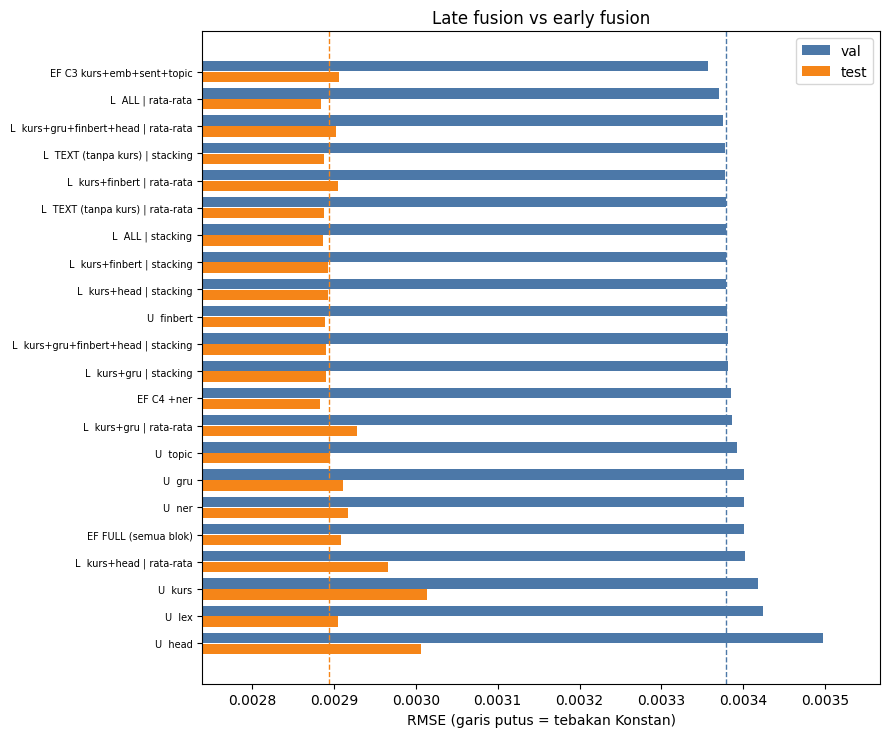

In [17]:
pl = reg_tbl[["RMSE val", "RMSE test"]].sort_values("RMSE val", ascending=False)
const = {sp: evaluate(y[m], const_p[m])["RMSE"] for sp, m in (("val", va), ("test", te))}
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(pl)))); yy = np.arange(len(pl))
ax.barh(yy + 0.2, pl["RMSE val"], height=0.38, label="val", color="#4C78A8"); ax.barh(yy - 0.2, pl["RMSE test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(pl.index, fontsize=7); ax.set_xlim(pl.min().min() * 0.95, pl.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend(); ax.set_title("Late fusion vs early fusion"); plt.tight_layout(); plt.show()

### 7.4 Uji berpasangan (block bootstrap)
Sama dengan early fusion: selisih MSE per hari terhadap **A** dan **Konstan** dengan selang 95% (blok 10 hari), val dan test terpisah, dalam % MSE pembanding. Negatif = lebih baik. Selang yang memuat 0 = tidak bisa dibedakan.

In [18]:
rng = np.random.default_rng(SEED)
def block_boot(d, block=10, nrep=2000):
    n = len(d); nb = int(np.ceil(n / block)); starts = np.arange(n - block + 1); means = np.empty(nrep)
    for r in range(nrep):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.choice(starts, nb)])[:n]; means[r] = d[idx].mean()
    return d.mean(), *np.percentile(means, [2.5, 97.5])

out = []
for name, p in REG.items():
    if name == "U  kurs": continue
    r = {"set": name}
    for sp, mask in (("val", va), ("test", te)):
        yy_ = y[mask]; se = lambda q: (yy_ - q[mask]) ** 2
        for rn, ref in (("A", REG["U  kurs"]), ("Konstan", const_p)):
            m, lo, hi = block_boot(se(p) - se(ref)); b = se(ref).mean()
            r[f"{sp} vs {rn}"] = f"{100 * m / b:+.1f}% [{100 * lo / b:+.1f}, {100 * hi / b:+.1f}]"
    out.append(r)
pd.DataFrame(out).set_index("set")

,val vs A,val vs Konstan,test vs A,test vs Konstan
set,,,,
U gru,"-1.0% [-6.9, +4.7]","+1.3% [-3.4, +6.0]","-6.7% [-17.0, +1.0]","+1.2% [-4.1, +5.8]"
U lex,"+0.4% [-5.3, +7.2]","+2.7% [-0.5, +5.8]","-7.1% [-17.2, +1.7]","+0.7% [-4.0, +6.9]"
U finbert,"-2.2% [-8.2, +4.2]","+0.1% [-3.5, +2.9]","-8.1% [-20.1, +1.0]","-0.3% [-4.6, +4.5]"
U head,"+4.7% [-2.2, +13.0]","+7.1% [+0.4, +13.6]","-0.5% [-10.1, +8.5]","+7.9% [+3.0, +13.9]"
U topic,"-1.5% [-6.5, +4.2]","+0.8% [-3.9, +5.0]","-7.7% [-19.3, +2.3]","+0.1% [-4.6, +5.7]"
U ner,"-1.0% [-7.4, +6.1]","+1.3% [-3.0, +5.1]","-6.3% [-14.6, -0.5]","+1.6% [-3.3, +6.1]"
L kurs+gru | rata-rata,"-1.8% [-4.9, +1.2]","+0.4% [-3.7, +4.0]","-5.6% [-11.4, -1.4]","+2.3% [-2.0, +6.6]"
L kurs+gru | stacking,"-2.1% [-7.4, +3.3]","+0.1% [-2.4, +2.6]","-8.0% [-17.9, -0.7]","-0.3% [-3.2, +2.3]"
L kurs+finbert | rata-rata,"-2.3% [-5.5, +0.9]","-0.1% [-2.8, +2.7]","-7.1% [-12.7, -2.6]","+0.8% [-2.5, +4.6]"


## 8. Catatan metodologi
- **Tanpa kebocoran:** pakar dilatih hanya pada train; model meta dilatih pada prediksi out-of-fold (validasi berurutan) di train, lalu dipakai ke val/test. Standardisasi, PCA, BERTopic, dan scaler di-fit di train.
- **Head Transformer bersifat frozen:** MLP kecil di atas embedding FinBERT beku (bukan fine-tuning). Dengan ±830 hari train dan 768 dimensi, head sangat rawan overfit; early stopping (ekor train), dropout, dan weight decay dipakai.
- **Stacking dengan sinyal lemah:** bobot non-negatif cenderung menyusut ke intersep. Itu perilaku yang diharapkan, bukan galat.
- **Dua keluaran terpisah:** prediksi return dan logit arah dilatih terpisah pada pakar tabular, bersama (multi-tugas) pada pakar neural.
- **Banyak set diuji**; selisih kecil yang tidak konsisten antara val dan test kemungkinan kebetulan.
- **Pembanding utama tetap baris Konstan** (regresi) dan prior (arah).

## 9. Kesimpulan
1. **Pakar tunggal (U):** modalitas mana yang paling informatif sendirian (error dan AUC)? Apakah GRU lebih baik dari pakar `kurs`? Apakah head atas FinBERT lebih baik dari model tabular atas fitur FinBERT-PCA?
finbert, topic, ner, gru, dan lex semuanya berada di sekitar Konstan (−0.3% sampai +1.6%). Tidak ada modalitas yang menonjol.
gru sedikit lebih baik dari kurs (−0.5% val, −3.4% test) tapi tidak signifikan. Tidak ada bukti memori temporal yang berguna.
head (MLP atas FinBERT 768-d) paling buruk dan signifikan lebih buruk dari Konstan (+7.1% val, +7.9% test). Dengan sekitar 830 hari dan 768 dimensi, dia overfit meski sudah pakai dropout dan early stopping. Ini temuan yang jelas dan layak masuk laporan.
kurs sendiri lebih buruk dari Konstan, jadi memang tidak ada sinyal di fitur kurs.

2. **Late fusion vs pakar terbaik:** apakah rata-rata atau stacking lebih baik dari pakar tunggal terbaik? Bobot stacking menunjukkan pakar mana yang dipakai.
Rata-rata sedikit lebih baik di test (L ALL rata-rata 0.00288) karena menurunkan varians. Tapi itu bukan peningkatan sinyal, hanya prediksi yang lebih "jinak".

3. **Late vs early (7.1 dan 7.4):** pada pakar yang sama, mana yang lebih baik dalam error dan dalam AUC?
Setara. L ALL rata-rata dan EF C4 sama-sama 0.00288 di test dan 0.00337–0.00338 di val. Menggabungkan di tingkat keputusan tidak menambah apa pun dibanding menggabungkan fitur.

Angka early fusion di sini sedikit beda dari notebook sebelumnya (mis. C4 test 0.00288 vs 0.00291). Selisih sekecil itu masih dalam noise.

4. **Arah (7.2):** adakah set dengan AUC secara konsisten di atas 0,5 pada val dan test, dan log-loss di bawah prior?
Hampir semua AUC sekitar 0.5 dan tidak konsisten: C3 val 0.596 tapi test 0.506, finbert 0.577 vs 0.499, gru 0.493 vs 0.587.
Sedikit di atas 0.5 di kedua split: kurs+gru+finbert+head rata-rata (0.547 / 0.561), head (0.553 / 0.532), L ALL rata-rata (0.525 / 0.542). Dengan sekitar 180 hari per split, SE AUC sekitar 0.04, jadi ini hanya sekitar 1 SE dan tidak bisa diklaim.
Selain itu, BalAcc dan MCC pada set tersebut tidak mendukung: MCC test −0.05 sampai +0.02. Log-loss terhadap prior juga sekitar 0 atau lebih buruk.

5. Apakah ada yang melampaui Konstan, dengan selang yang tidak memuat 0?